# Project links

**Github repository**
https://github.com/phkhle/IND320/tree/project3

**Streamlitt app**
https://ind320-h2026.streamlit.app/


In [1]:
import geopandas as gpd
import sys
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Get the parent directory, since the notebook is located one folder below the project root
project_root = Path.cwd().parent
# Add the project root to Python's module search path
# This allows Python to find and import modules from src/
sys.path.insert(0, str(project_root))

from src.forecasting import forecast_reservoir, evaluate_multistep_forecast, forecast_reservoir_snarimax, evaluate_forecasting_models
from src.forecasting import evaluate_history_length

import matplotlib.pyplot as plt
import plotly.graph_objects as go

from src.forecasting import tune_snarimax


from src.NVE_API import get_nve_data


# Download Euro, USD currency exchange rates

# Streamlit application 

## Structure and navigation

For Project 4, the Streamlit dashboard is reorganised according to the purpose of each page rather than only the data source.

The application is divided into three main sections:

- Explore Data: 
    - Interactive Map
    - Reservoir Statistics 
    - Electricity Transfer
    - Currency Exchange.

- Analysis: 
    - STL and Spectrogram
    - Weather Anomalies
    - Sliding Window Correlation.

- Forecasting: Reservoir Filling Forecast.

A separate Home page provides an overview of the dashboard and its data sources.

The navigation was implemented using ``st.navigation()`` and ``st.Page()``. Pages can then be grouped into logical sections.

Shared geographical selections will be stored using ``st.session_state``. Users will be able to select an area on the interactive map and reuse that selection in other analyses.



## Interactive map (XXX)

## Create GeoJSON

Create geographic file for the electricity pricing areas (EL)

In [2]:
# Load electricity price areas
price_areas = gpd.read_file(
    "../data/shapefiles/Budområder.shp"
)

# Convert to WGS84 coordinates
price_areas = price_areas.to_crs(epsg=4326)

# Standardize region names
price_areas["region"] = (
    price_areas["budomr"]
    .str.replace(" ", "", regex=False)
)

# Save as GeoJSON
price_areas[["region", "geometry"]].to_file(
    "../data/price_areas.geojson",
    driver="GeoJSON"
)

print("GeoJSON for electricity price areas created successfully!")

GeoJSON for electricity price areas created successfully!


Create geographic file for the precipitation areas

In [3]:
# Load rain areas
regions = gpd.read_file("../data/shapefiles/NVE_region.shp", encoding = 'utf-8')

# Map NVE administrative regions to precipitation regions
region_mapping = {
    "RS": "Øst",
    "RØ": "Øst",
    "RV": "Vest",
    "RM": "Nord",
    "RN": "Nord"
}

# Assign precipitation region names
precipitation_regions = regions.copy()
precipitation_regions["region"] = precipitation_regions["REGION"].map(region_mapping)

# Merge polygons belonging to the same precipitation region
precipitation_regions = precipitation_regions.dissolve(
    by="region",
    as_index=False
)

# Convert precipitation regions to WGS84
weather_regions_geojson = precipitation_regions.to_crs(epsg=4326)

# Keep only region names and geometry
weather_regions_geojson = weather_regions_geojson[
    ["region", "geometry"]
]

# Export as GeoJSON
weather_regions_geojson.to_file(
    "../data/weather_regions.geojson",
    driver="GeoJSON"
)

print("Weather regions GeoJSON created successfully!")

Weather regions GeoJSON created successfully!


Create geographic file for the water areas (river basin areas - VASS)

In [4]:
# Load water areas
water_regions = gpd.read_file("../data/shapefiles/Vassdragsomrade.shp", encoding = 'utf-8')
# Convert to WGS84 coordinates
water_regions = water_regions.to_crs(epsg=4326)


# Standardize region names
water_regions["region"] = (
    water_regions["vassdragso"]
    .str.replace(" ", "", regex=False)
)

# Save as GeoJSON
water_regions[["region", "geometry"]].to_file(
    "../data/water_areas.geojson",
    driver="GeoJSON"
)


In [5]:
import geopandas as gpd

water_regions = gpd.read_file("../data/water_areas.geojson")

print("Antall områder:", len(water_regions))
print("Kolonner:", water_regions.columns.tolist())

display(water_regions[["region"]])

Antall områder: 205
Kolonner: ['region', 'geometry']


,region
0,196
1,191
2,190
3,189
4,315
...,...
200,005
201,004
202,003
203,002


# Forecasting

## Historical evaluation of 1 week forecasting

### Online evaluation with Lag-based Linear Regression model

In [6]:
# Retrieve reservoir data from NVE API
df_nve = get_nve_data()

# Select NO3
df_region = df_nve[
    (df_nve["omrType"] == "EL") &
    (df_nve["omrnr"] == 3)
].copy()


Lag-based Linear Regression (using River library) was trained with historical data from first observation available until before the last 52 weeks. 

Evaluation: Lag-based Linear Regression predicted one week ahead in the period of the last 52 weeks.

Updating process happened under the evaluation. Lag-based Linear Regression was updated with acutal value after every prediction. This means the model would gradually get more training data through the evaluation period

In [7]:
dates = (
    pd.to_datetime(df_region["dato_Id"])
    .drop_duplicates()
    .sort_values()
    .reset_index(drop=True)
)

test_weeks = 52

print("========== TRAINING ==========")
print("Start:", dates.iloc[0].date())
print("End:  ", dates.iloc[-(test_weeks + 1)].date())
print("Weeks:", len(dates) - test_weeks)

print("\n========== EVALUATION ==========")
print("Start:", dates.iloc[-test_weeks].date())
print("End:  ", dates.iloc[-1].date())
print("Weeks:", test_weeks)

========== TRAINING ==========
Start: 1995-01-08
End:   2025-11-16
Weeks: 1611

========== EVALUATION ==========
Start: 2025-11-23
End:   2026-11-15
Weeks: 52


Train River and evaluate one week ahead, then compare with the baseline model



In [8]:
results = forecast_reservoir(
    df=df_region,
    n_lags=4,
    test_weeks=52
)

results.head()

,date,actual,predicted
0,2025-11-23,0.851878,0.866210
1,2025-11-30,0.824069,0.842509
2,2025-12-07,0.795395,0.804163
3,2025-12-14,0.774006,0.767300
4,2025-12-21,0.766409,0.748065


In [9]:


mae = mean_absolute_error(
    results["actual"],
    results["predicted"]
)

rmse = np.sqrt(mean_squared_error(
    results["actual"],
    results["predicted"]
))

print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")

MAE: 0.0179
RMSE: 0.0218


### Baseline model

The baseline assumes that the fill rate next week will be equal to the most recent observed value. 

Baseline uses actual observations from the previous week, even when this falls within the evaluation period. This is permitted in a one-week forecast, as the value is already known at the time of prediction.

In [10]:

# Baseline: previous week's filling
df_region["baseline"] = df_region["fyllingsgrad"].shift(1)

# Use exactly the same dates as used in River model
baseline_df = results.merge(
    df_region[["dato_Id", "baseline"]],
    left_on="date",
    right_on="dato_Id",
    how="left"
)

# Remove missing values
baseline_df = baseline_df.dropna(
    subset=["actual", "predicted", "baseline"]
)

In [11]:
print("========== BASELINE ==========")
print("Training: None")
print("Evaluation start:", baseline_df["date"].min())
print("Evaluation end:  ", baseline_df["date"].max())
print("Evaluated weeks: ", len(baseline_df))

========== BASELINE ==========
Training: None
Evaluation start: 2025-11-23 00:00:00
Evaluation end:   2026-11-15 00:00:00
Evaluated weeks:  52


### Compare Lag-based Linear Regression (River) and Baseline

In [12]:
# Evaluate both models
evaluation = []

for model_name, pred_col in [
    ("River", "predicted"),
    ("Baseline", "baseline")
]:
    y_true = baseline_df["actual"]
    y_pred = baseline_df[pred_col]

    evaluation.append({
        "Model": model_name,
        "MAE (pp)": mean_absolute_error(y_true, y_pred) * 100,
        "RMSE (pp)": np.sqrt(mean_squared_error(y_true, y_pred)) * 100,
        "R²": r2_score(y_true, y_pred)
    })

evaluation_df = pd.DataFrame(evaluation).set_index("Model")

display(evaluation_df.round(4))

,MAE (pp),RMSE (pp),R²
Model,,,
River,1.7916,2.1807,0.9869
Baseline,2.4360,3.0702,0.9739


The River model outperforms the baseline on all three evaluation metrics.

However, we have so far only evaluated one week ahead, with the model being updated on an ongoing basis.

This means that these results do not tell us how well the model will predict maximum 12 weeks ahead without new observations.
Therefore I extend the model to multi-step forecasting (1–12 weeks ahead).

We can retain the existing River model as a starting point and later compare it with SNARIMAX.

## Historical evaluation of 12 weeks forecasting

the new River model was for 12-week forecasting, and regardign the new baseline: the most recent observed fill level at the start of each forecast period is used as the forecast for all 12 future weeks, then the two models were compared with each other in the validation set (all included in the `evaluate_multistep_forecast` function)

### River and Baseline

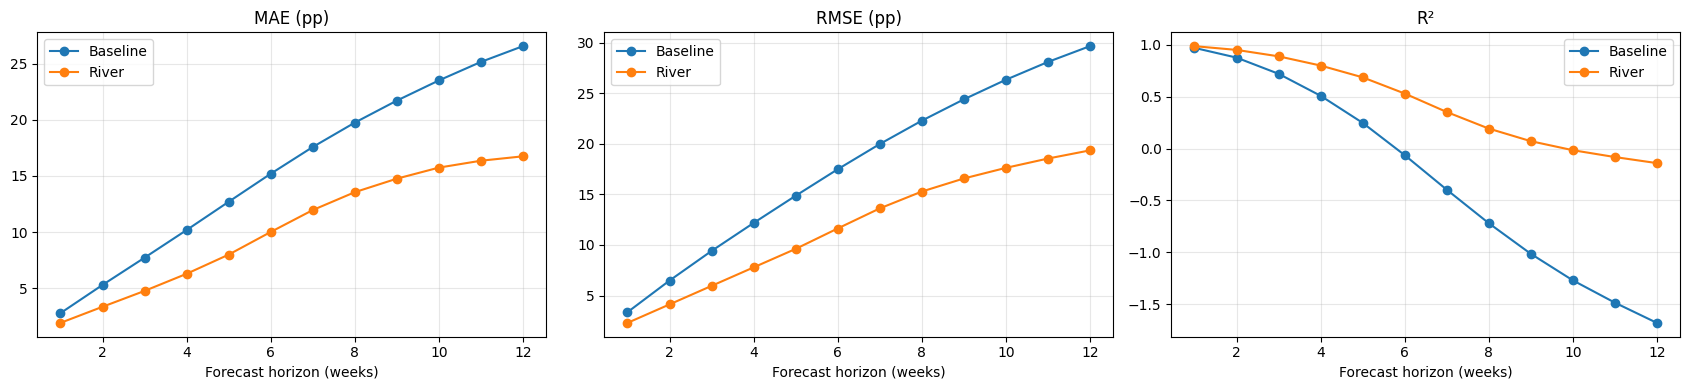

In [13]:

predictions, metrics_df = evaluate_multistep_forecast(
    df=df_region,
    n_lags=4,
    horizon=12,
    test_weeks=52
)


fig, axes = plt.subplots(1, 3, figsize=(17, 4))

for i, metric in enumerate(["MAE (pp)", "RMSE (pp)", "R²"]):

    for model_name, group in metrics_df.groupby("Model"):

        axes[i].plot(
            group["Horizon"],
            group[metric],
            marker="o",
            label=model_name
        )

    axes[i].set_title(metric)
    axes[i].set_xlabel("Forecast horizon (weeks)")
    axes[i].grid(alpha=0.3)
    axes[i].legend()

plt.tight_layout()
plt.show()

the River model works well in the short term, but struggles to predict reservoir levels far into the future.

The model uses only the last four weeks:
n_lags = 4. Consequently, it has limited information about annual seasonal patterns.

### SNARIMAX

Create a simple parameter search function for SNARIMAX, which evaluates different configurations using MAE, RMSE and R² over 12 forecast weeks. 

Similar to River model, The last 52 weeks of ``df_region`` are reserved for final model evaluation

*Validation period **for tuning*** is the 52 weeks right before the model evaluation period


In [14]:
# 1. Find best SNARIMAX parameters on validation data FOR TUNING

tuning_results, best_params = tune_snarimax(
    df=df_region,
    horizon=12,
    val_weeks=52,
    origin_step=4
)

display(tuning_results.round(4))

print("Best parameters:", best_params)

1/8 completed
2/8 completed
3/8 completed
4/8 completed
5/8 completed
6/8 completed
7/8 completed
8/8 completed


,p,d,q,m,sp,sd,sq,MAE (pp),RMSE (pp),R²,N predictions
0,1,1,2,52,2,0,0,5.5809,6.7140,0.8183,132
1,1,1,1,52,2,0,0,5.6825,6.8275,0.8121,132
2,2,1,2,52,2,0,0,5.6761,6.8645,0.8100,132
3,2,1,1,52,2,0,0,5.8270,7.0604,0.7990,132
4,1,1,2,52,1,0,0,5.9636,7.3068,0.7848,132
5,1,1,1,52,1,0,0,6.0961,7.4071,0.7788,132
6,2,1,2,52,1,0,0,6.1407,7.4882,0.7739,132
7,2,1,1,52,1,0,0,6.2166,7.5948,0.7674,132


Best parameters: {'p': 1, 'd': 1, 'q': 2, 'm': 52, 'sp': 2, 'sd': 0, 'sq': 0}


In [15]:
# 2. Compare all three models on validation data for MODELS (the last 52 weeks of df_region)

predictions_test, metrics_test = evaluate_forecasting_models(
    df=df_region,
    horizon=12,
    test_weeks=52,
    n_lags=4,
    snarimax_params=best_params
)


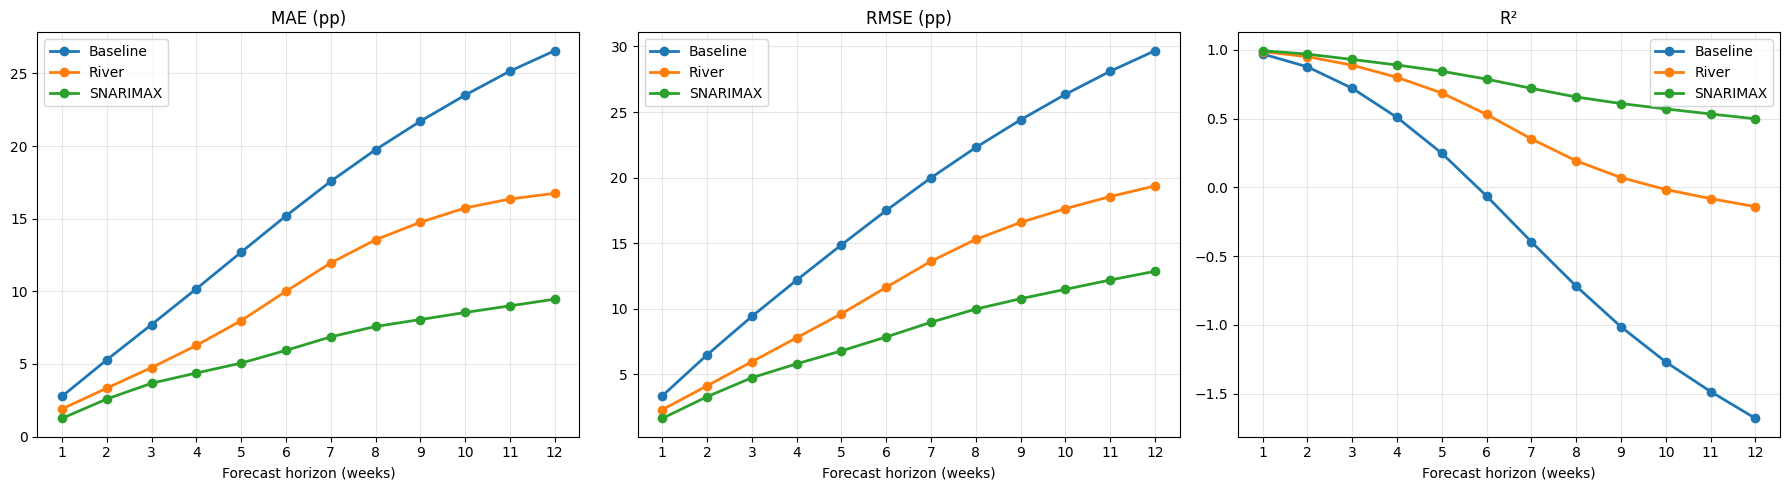

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

metrics = ["MAE (pp)", "RMSE (pp)", "R²"]

for i, metric in enumerate(metrics):

    for model_name, group in metrics_test.groupby("Model"):

        group = group.sort_values("Horizon")

        axes[i].plot(
            group["Horizon"],
            group[metric],
            marker="o",
            linewidth=2,
            label=model_name
        )

    axes[i].set_title(metric)
    axes[i].set_xlabel("Forecast horizon (weeks)")
    axes[i].set_xticks(range(1, 13))
    axes[i].grid(alpha=0.3)
    axes[i].legend()

plt.tight_layout()
plt.show()

The models are retrained at the start of each forecast period using the same available historical data, whereas the baseline requires no training. Here we see that, even though the models tend to degrade progressively after week 6, SNARIMAX remains the most stable model, maintaining positive $R^2$ values above 0.5 throughout

## Customise training history

investigate which history length works best. We can compare 5, 10 and 20 years, as well as the entire historical data set, over the same evaluation period, using the same SNARIMAX parameters and the same forecast horizon.

Note: We continue to use the last 52 weeks as the validation set for model selection. We now also use this period to determine the historical data length. It is therefore not an independent test set.

In [24]:

predictions_history, metrics_history, runtime_history = (
    evaluate_history_length(
        df=df_region,
        history_years_list=[5, 10, 20, None],
        horizon=12,
        val_weeks=52,
        origin_step=1,
        snarimax_params=best_params
    )
)

display(metrics_history.round(4).head())
display(runtime_history.round(2))

Evaluating 5 years...
Evaluating 10 years...
Evaluating 20 years...
Evaluating Full history...


,History,Horizon,MAE (pp),RMSE (pp),R²
0,10 years,1,1.2538,1.6124,0.9929
1,10 years,2,2.5831,3.2506,0.9687
2,10 years,3,3.6533,4.6865,0.9305
3,10 years,4,4.3583,5.7357,0.8909
4,10 years,5,5.0218,6.7172,0.8465


,History,Runtime (s)
0,5 years,0.36
1,10 years,0.52
2,20 years,0.86
3,Full history,1.04


Visualize the prediction's performance

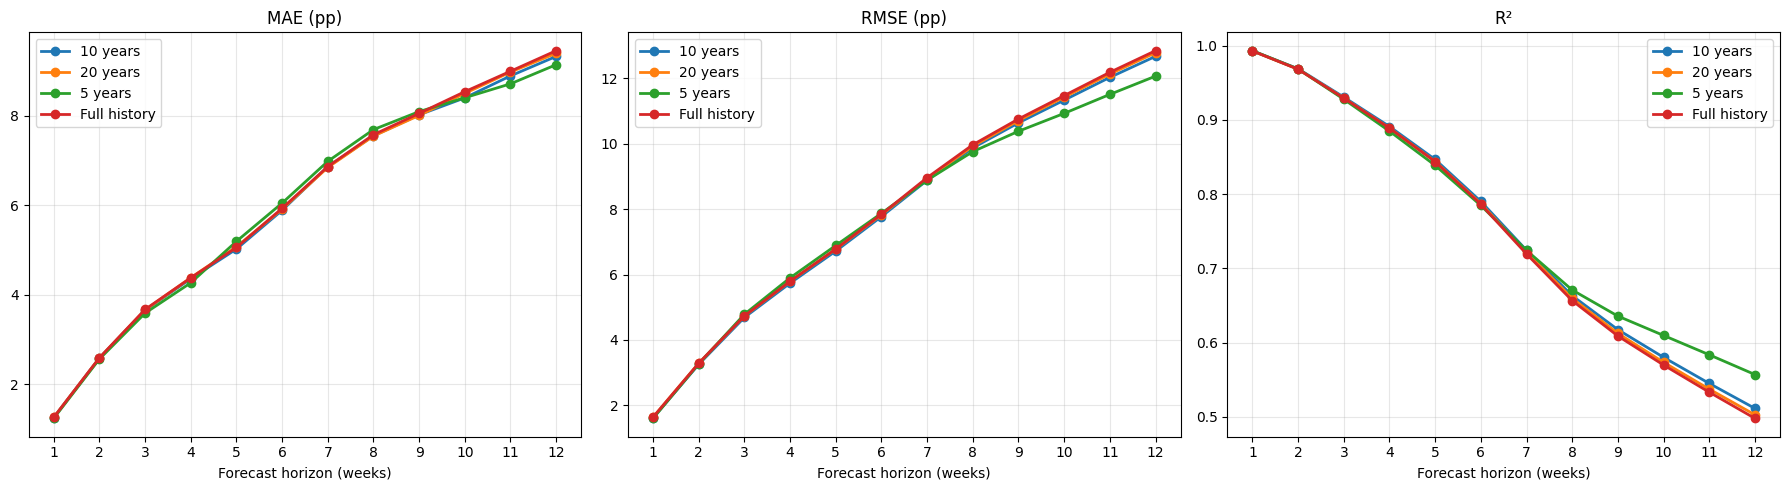

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

metrics = ["MAE (pp)", "RMSE (pp)", "R²"]

for i, metric in enumerate(metrics):

    for history, group in metrics_history.groupby("History"):

        group = group.sort_values("Horizon")

        axes[i].plot(
            group["Horizon"],
            group[metric],
            marker="o",
            linewidth=2,
            label=history
        )

    axes[i].set_title(metric)
    axes[i].set_xlabel("Forecast horizon (weeks)")
    axes[i].set_xticks(range(1, 13))
    axes[i].grid(alpha=0.3)
    axes[i].legend()

plt.tight_layout()
plt.show()

Summary of the averaged performance and running time

In [26]:
summary_history = (
    metrics_history
    .groupby("History")[["MAE (pp)", "RMSE (pp)", "R²"]]
    .mean()
    .reset_index()
    .merge(runtime_history, on="History")
    .sort_values("RMSE (pp)")
)

display(summary_history.round(4))

,History,MAE (pp),RMSE (pp),R²,Runtime (s)
2,5 years,5.9946,7.8212,0.7647,0.3562
0,10 years,5.9858,7.9351,0.7550,0.5166
1,20 years,6.0128,7.9959,0.7514,0.8599
3,Full history,6.0318,8.0234,0.7494,1.0443


We find that a 5-year training history provides better predictive performance over longer forecast horizons than the full history.

Possible explanations include:
- More recent observations may be more representative of current conditions.
- Seasonal patterns may have changed over time.

Therefore I choose  a 5-year training history as the default setting in Streamlit, because it offers better performance over longer time horizons and require less computation time.

## Exogenous variables i SNARIMAX

## Final model training with the best model and future forecasting (usikker)

Now I will train the best model with the entire df_region, then use it for future forecasting. ``forecast_reservoir_snarimax`` fetch updated data when the fucntion is called and retrain the model on the the latest 5 years history og make a new 12-week forecasting

In [ ]:
# Retrain the selected model on all available historical data
# and forecast the next 12 weeks

forecast_future = forecast_reservoir_snarimax(
    df=df_region, # Use the enire dataset, including the last 52 weeks
    horizon=12, # predict the next 12 weeks that we haven't observed
    history_weeks=52*5, # the model will be trained 
    **best_params # Use the optimal parameters from the tuning
)

display(forecast_future)

,date,predicted
0,2026-11-22,0.672220
1,2026-11-29,0.647029
2,2026-12-06,0.622376
3,2026-12-13,0.596327
4,2026-12-20,0.574498
5,2026-12-27,0.557273
6,2027-01-03,0.532478
7,2027-01-10,0.499301
8,2027-01-17,0.473631
9,2027-01-24,0.441854


In [28]:
# Historical observations
df_history = df_region.copy()
df_history["dato_Id"] = pd.to_datetime(df_history["dato_Id"])
df_history = df_history.sort_values("dato_Id").tail(52)

# Future predictions
df_forecast = forecast_future.copy()

fig = go.Figure()

# Actual historical values
fig.add_trace(go.Scatter(
    x=df_history["dato_Id"],
    y=df_history["fyllingsgrad"] * 100,
    mode="lines",
    name="Actual",
    line=dict(color="royalblue", width=2)
))

# Future forecast
fig.add_trace(go.Scatter(
    x=df_forecast["date"],
    y=df_forecast["predicted"] * 100,
    mode="lines+markers",
    name="SNARIMAX forecast",
    line=dict(color="orange", width=2, dash="dash")
))

# Mark the forecast origin
fig.add_shape(
    type="line",
    x0=df_history["dato_Id"].max(),
    x1=df_history["dato_Id"].max(),
    y0=0,
    y1=1,
    yref="paper",
    line=dict(color="gray", dash="dot")
)

fig.update_layout(
    title="NO3 – Reservoir Filling: Historical Data and 12-Week Forecast",
    xaxis_title="Date",
    yaxis_title="Reservoir filling (%)",
    hovermode="x unified",
    template="plotly_white",
    height=500
)

fig.update_yaxes(range=[0, 100])

fig.show()